## Ejercicio hiperparametrización breast cancer de sklearn

1. Carga el dataset [breast_cancer de `sklearn`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
2. Prueba al menos 5 modelos diferentes de clasificación y aplica un GridSearchCV mediante Pipelines. Aplica también un RandomizedSearchCV.
3. Conclusiones. Guarda el modelo final en un archivo con pickle.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

In [2]:
%matplotlib inline
data = load_breast_cancer()
data

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]], shape=(569, 30)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,

In [3]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [4]:
print(data['DESCR'])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [5]:
df = pd.DataFrame(data['data'], columns=data['feature_names'])
df['target'] = data['target']
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [6]:
sns.pairplot(df)

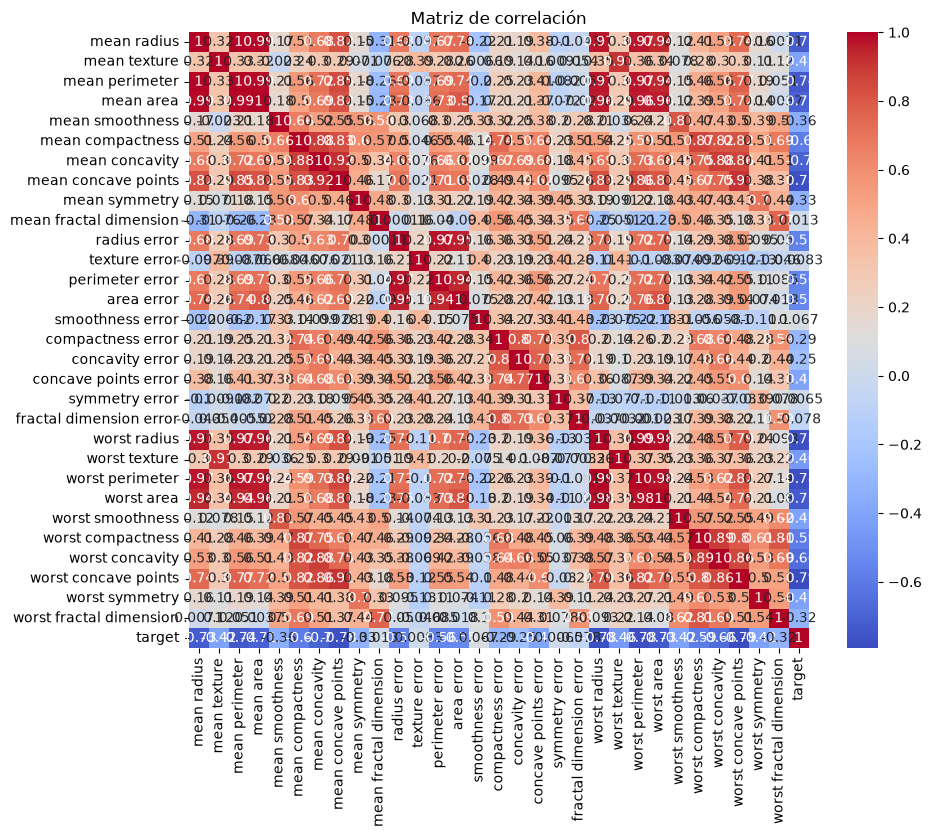

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only= True), annot=True, cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

In [8]:
df["target"].value_counts()

target
1    357
0    212
Name: count, dtype: int64

In [10]:
from data_profiling import ProfileReport

c:\Users\ngo1\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
profile = ProfileReport(df, title="Profiling Report")
profile.to_file("your_report.html")

Export report to file: 100%|██████████| 1/1 [00:00<00:00,  5.19it/s]


In [12]:
# Lista de las 20 variables a eliminar (15 por multicolinealidad + 5 por baja correlación)
cols_a_eliminar = [
    # Multicollinearity (> 0.90) 
    'worst radius', 'worst area', 'mean perimeter', 'mean radius', 'mean area',
    'perimeter error', 'area error',
    'mean concave points', 'mean concavity', 'worst concavity',
    'worst compactness',
    'mean texture',
    # Baja correlación con target (< 0.25)
    'texture error', 'smoothness error', 'mean fractal dimension', 
    'fractal dimension error', 'symmetry error'
]


In [20]:
import pandas as pd
import numpy as np

# -------------------------------------------------------------
# CONFIGURACIÓN
# -------------------------------------------------------------
umbral_target = 0.10      # correlación mínima con target
umbral_multicol = 0.9    # correlación máxima entre predictores


corr = df.corr()

# -------------------------------------------------------------
# 1. ELIMINAR VARIABLES CON BAJA CORRELACIÓN CON TARGET
# -------------------------------------------------------------
corr_target = corr["target"].abs()
variables_baja_corr = corr_target[corr_target < umbral_target].index.tolist()

print("Variables con baja correlación con target (<0.10):")
print(variables_baja_corr)

# -------------------------------------------------------------
# 2. DETECTAR MULTICOLINEALIDAD EXTREMA ENTRE PREDICTORES
# -------------------------------------------------------------
variables = corr.columns.tolist()
variables.remove("target")

# Matriz de correlaciones solo entre predictores
corr_pred = corr.loc[variables, variables].abs()

# Lista para eliminar
eliminar_multicol = set()

# Recorremos pares de variables
for var1 in variables:
    for var2 in variables:
        if var1 != var2 and corr_pred.loc[var1, var2] > umbral_multicol:
            # Nos quedamos con la variable más correlacionada con target
            if corr_target[var1] < corr_target[var2]:
                eliminar_multicol.add(var1)
            else:
                eliminar_multicol.add(var2)

print("Variables redundantes por multicolinealidad (>0.95):")
print(list(eliminar_multicol))

# -------------------------------------------------------------
# 3. VARIABLES FINALES A CONSERVAR
# -------------------------------------------------------------
variables_eliminar = set(variables_baja_corr) | eliminar_multicol
variables_finales = [v for v in corr.columns if v not in variables_eliminar]

print("✅ Variables finales recomendadas:")
print(variables_finales)

Variables con baja correlación con target (<0.10):
['mean fractal dimension', 'texture error', 'smoothness error', 'symmetry error', 'fractal dimension error']
Variables redundantes por multicolinealidad (>0.95):
['mean area', 'mean radius', 'worst area', 'mean concave points', 'area error', 'mean concavity', 'mean texture', 'perimeter error', 'mean perimeter', 'worst radius']
✅ Variables finales recomendadas:
['mean smoothness', 'mean compactness', 'mean symmetry', 'radius error', 'compactness error', 'concavity error', 'concave points error', 'worst texture', 'worst perimeter', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']


In [ ]:
# df_limpio = df.drop(columns=cols_a_eliminar)

In [21]:
df_limpio = df[variables_finales]

In [22]:
df_limpio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean smoothness          569 non-null    float64
 1   mean compactness         569 non-null    float64
 2   mean symmetry            569 non-null    float64
 3   radius error             569 non-null    float64
 4   compactness error        569 non-null    float64
 5   concavity error          569 non-null    float64
 6   concave points error     569 non-null    float64
 7   worst texture            569 non-null    float64
 8   worst perimeter          569 non-null    float64
 9   worst smoothness         569 non-null    float64
 10  worst compactness        569 non-null    float64
 11  worst concavity          569 non-null    float64
 12  worst concave points     569 non-null    float64
 13  worst symmetry           569 non-null    float64
 14  worst fractal dimension  5

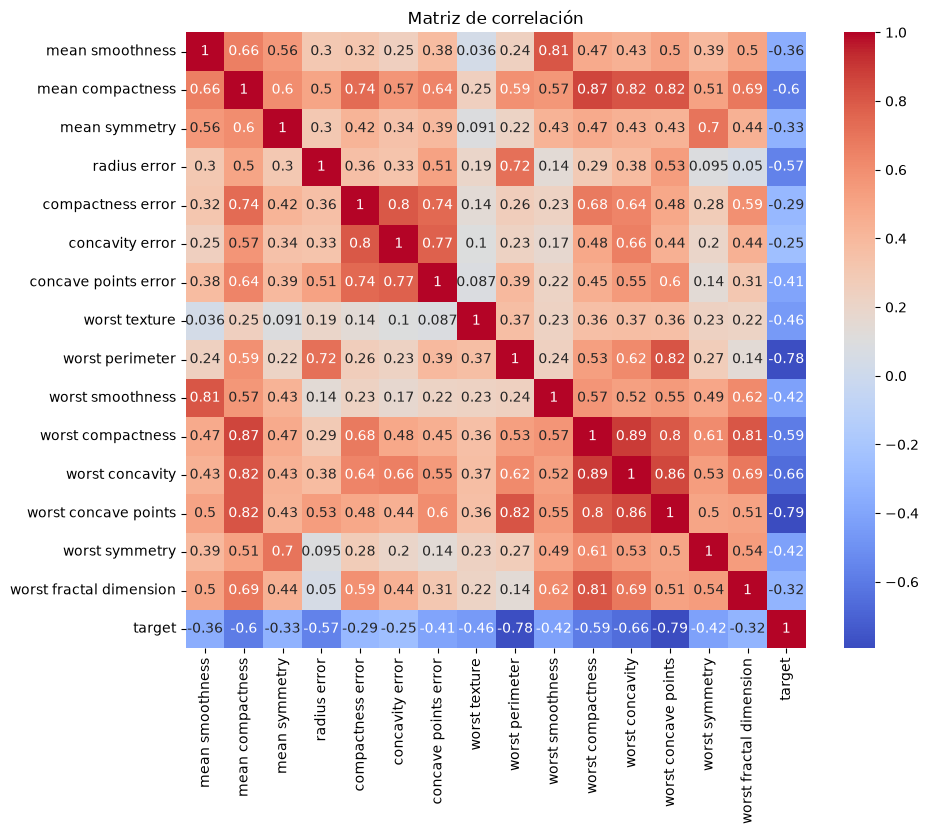

In [23]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_limpio.corr(numeric_only= True), annot=True, cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

In [24]:
from sklearn.model_selection import train_test_split

X = df_limpio.drop("target", axis=1)
y = df_limpio["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify= y)


In [26]:
from sklearn import svm
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, make_scorer, recall_score

In [29]:
pipe = Pipeline(steps=[("scaler", StandardScaler()),
    ('classifier', RandomForestClassifier())
])

logistic_params = {
    'classifier': [LogisticRegression(max_iter=1000, solver='liblinear'), LogisticRegression(max_iter=10, solver='liblinear')],
    'classifier__l1_ratio': [1, 0]
}

random_forest_params = {
    'scaler': [StandardScaler(), MinMaxScaler()],
    'classifier': [RandomForestClassifier(random_state= 42)],
    'classifier__max_depth': [2,3,5]
}

svm_params = {
    'classifier': [svm.SVC()], # kernel rbf (gaussiano)
    'classifier__C': [0.001, 0.1, 0.5, 1, 5, 10, 100],
}

knn_params = {
    'scaler': [StandardScaler(), MinMaxScaler()],
    'classifier': [KNeighborsClassifier()],
    'classifier__n_neighbors': [3, 5, 7],
    'classifier__weights': ['uniform', 'distance']
}

gb_params = {
    'scaler': [StandardScaler(), MinMaxScaler()],
    'classifier': [GradientBoostingClassifier(random_state=42)],
    'classifier__n_estimators': [100, 200],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__max_depth': [2, 3]
}

search_space = [
    logistic_params,
    random_forest_params,
    svm_params,
    knn_params,
    gb_params
]

recall_maligno = make_scorer(recall_score, pos_label=0)

clf = GridSearchCV(estimator = pipe,
                  param_grid = search_space,
                  cv = 5,
                  scoring= recall_maligno,
                  n_jobs=-1)

clf.fit(X_train, y_train)

c:\Users\ngo1\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'classifier': [LogisticRegre...r='liblinear'), LogisticRegre...r='liblinear')], 'classifier__l1_ratio': [1, 0]}, {'classifier': [RandomForestC...ndom_state=42)], 'classifier__max_depth': [2, 3, ...], 'scaler': [StandardScaler(), MinMaxScaler()]}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(r..., pos_label=0)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an exa

In [30]:
print(clf.best_estimator_)
print(clf.best_score_)
print(clf.best_params_)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(l1_ratio=1, max_iter=10,
                                    solver='liblinear'))])
0.9588235294117646
{'classifier': LogisticRegression(max_iter=10, solver='liblinear'), 'classifier__l1_ratio': 1}


In [31]:
clf.best_estimator_.predict(X_test)
clf.best_estimator_.score(X_test,y_test)

0.9736842105263158

In [32]:
recall_score(y_test, clf.best_estimator_.predict(X_test), pos_label=0)

0.9761904761904762

In [33]:
random_clf = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=search_space,
    n_iter=15,
    cv=5,
    scoring= recall_maligno,
    random_state=42,
    n_jobs=-1
)

random_clf.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","[{'classifier': [LogisticRegre...r='liblinear'), LogisticRegre...r='liblinear')], 'classifier__l1_ratio': [1, 0]}, {'classifier': [RandomForestC...ndom_state=42)], 'classifier__max_depth': [2, 3, ...], 'scaler': [StandardScaler(), MinMaxScaler()]}, ...]"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","make_scorer(r..., pos_label=0)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted esti

In [34]:
print(random_clf.best_estimator_)
print(random_clf.best_score_)
print(random_clf.best_params_)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 GradientBoostingClassifier(max_depth=2, n_estimators=200,
                                            random_state=42))])
0.9529411764705882
{'scaler': StandardScaler(), 'classifier__n_estimators': 200, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.1, 'classifier': GradientBoostingClassifier(random_state=42)}


In [35]:
random_clf.best_estimator_.predict(X_test)
random_clf.best_estimator_.score(X_test,y_test)

0.9385964912280702

In [36]:
recall_score(y_test, random_clf.best_estimator_.predict(X_test), pos_label=0)

0.9047619047619048

In [37]:
best_model = clf.best_estimator_ if clf.best_score_ >= random_clf.best_score_ else random_clf.best_estimator_

In [38]:
print(classification_report(y_test, best_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.95      0.98      0.96        42
           1       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [39]:
print(classification_report(y_test, clf.best_estimator_.predict(X_test)))

              precision    recall  f1-score   support

           0       0.95      0.98      0.96        42
           1       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [40]:
print(classification_report(y_test, random_clf.best_estimator_.predict(X_test)))

              precision    recall  f1-score   support

           0       0.93      0.90      0.92        42
           1       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



In [41]:
import pickle

filename = 'mejor_modelo'

with open(filename, 'wb') as archivo_salida:
    pickle.dump(best_model, archivo_salida)

# Conclusiones

* Mejor modelo seleccionado: El mejor recall (y también accuracy) se ha obtenido mediante GridSearchCV con un pipeline formado por StandardScaler y **LogisticRegression** (solver='liblinear', l1_ratio=1), alcanzando un **95,88% de recall** en validación cruzada. 
    * Con RandomizedSearchCV, en cambio, el mejor candidato fue Gradient Boosting. No obstante, su puntuación ha sido ligeramente inferior, ya que no evalúa de forma exhaustiva todas las combinaciones de hiperparámetros.

* Elección de la métrica (Recall vs. Accuracy): Al tratarse de un problema médico de detección de cáncer, se ha optado por medir el recall en lugar del accuracy para minimizar los falsos negativos (casos malignos diagnosticados erróneamente como sanos). Además, dado que en este dataset las clases están invertidas (0 = Maligno y 1 = Benigno), se especificó pos_label=0 para asegurar que el modelo priorizara la detección de los tumores malignos.

* Evaluación final en Test: El modelo elegido generaliza bien ante datos nuevos, logrando un 97,62% de recall y un 97,37% de accuracy, por lo que es el modelo que finalmente se exporta con pickle.

In [ ]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression())
])


param_grid = [
    {
        'classifier': [LogisticRegression(max_iter=1000, random_state=42)],
        'classifier__C': [0.01, 0.1, 1, 10],
        'classifier__penalty': ['l2']
    },
    {
        'classifier': [SVC(random_state=42)],
        'classifier__C': [0.1, 1, 10],
        'classifier__kernel': ['linear', 'rbf'],
        'classifier__gamma': ['scale', 'auto']
    },
    {
        'classifier': [KNeighborsClassifier()],
        'classifier__n_neighbors':,
        'classifier__weights': ['uniform', 'distance']
    },
    {
        'classifier': [RandomForestClassifier(random_state=42)],
        'classifier__n_estimators':,
        'classifier__max_depth': [None, 5, 10]
    },
    {
        'classifier': [GradientBoostingClassifier(random_state=42)],
        'classifier__n_estimators':,
        'classifier__learning_rate': [0.05, 0.1, 0.2],
        'classifier__max_depth': [3, 5]
    }
]

# Ejecutamos GridSearchCV
grid_search = GridSearchCV(
    pipe, param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1
)
grid_search.fit(X_train, y_train)

print("Mejor modelo (GridSearchCV):", grid_search.best_params_)
print("Mejor score en validación cruzada:", round(grid_search.best_score_, 4))

# Evaluación en el conjunto de test
y_pred_grid = grid_search.predict(X_test)
print("Accuracy en Test (GridSearchCV):", round(accuracy_score(y_test, y_pred_grid), 4))